This notebook is made in order to understand how the data looks like.

In [1]:
# Necessary packages
import pandas as pd
import warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#Ignore warnings
warnings.filterwarnings('ignore')

In [2]:
# Loading in the data first
df = pd.read_csv("P1_2627_C1_Answers_Anon.csv", on_bad_lines='skip')
df.head()

,Student number (sorted),points,39,40,41,42,43,44,45,46,47
0,1,57.0000,A,D,B,C,EADI,e,C,5.0,30.0
1,2,42.5375,A,E,A,B,A,e,C,6.0,NaN
2,3,48.7000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,43.7000,A,C,A,B,FABJ,e,e,7.0,10.0
4,5,60.2000,A,D,A,C,FAHIJ,e,D,4.0,15.0


In [3]:
df_no_consent = df[df['39'].isna()]
df = df[df['39']=='A']

In [4]:
print(df.shape,df_no_consent.shape)

(182, 11) (67, 11)


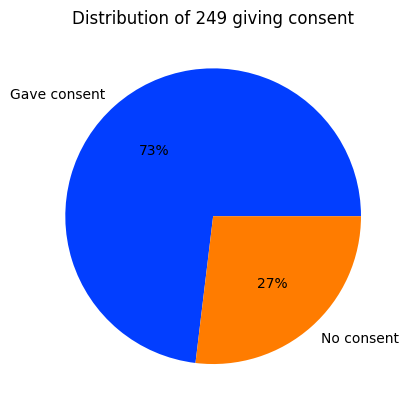

In [5]:
# Data and Labels
data = [df.shape[0],df_no_consent.shape[0]]
labels = ["Gave consent","No consent"]
# Colors
colors = sns.color_palette('bright') 

#Plotting pie chart
plt.pie(data, labels=labels, colors=colors, autopct='%.0f%%')
plt.title(f"Distribution of {data[0]+data[1]} giving consent")
plt.show()

Around 75% of the students filled in the survey and gave consent for it after finishing the programming 1 exam. We will only consider people who gave consent on using their data and leave the rest out.

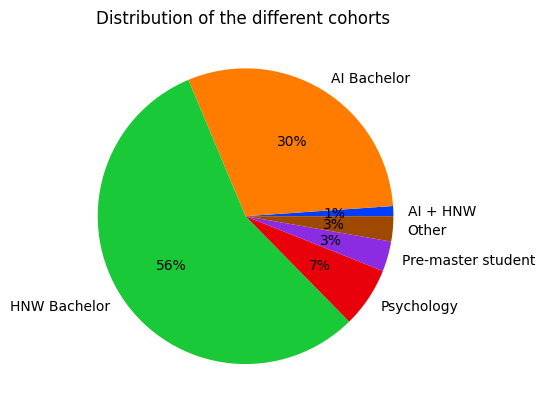

In [6]:
# Data and labels
label_names = ["AI + HNW","AI Bachelor","HNW Bachelor","Psychology","Pre-master student","Other"]
labels = ["AB","A","B","C","D","E"]
data = [df[df['40']==label].shape[0] for label in labels]

# Plotting pie char
plt.pie(data, labels=label_names, colors=colors, autopct='%.0f%%')
plt.title("Distribution of the different cohorts ")
plt.show()

More than half of the students who filled in the survey are part of the human neuroscience program, while around 30% follow the AI bachelor.

In [7]:
main_color = "#e3000b" # Radboud colors 

 https://www.ru.nl/medewerkers/services/campusfaciliteiten-gebouwen/communicatie-en-promotie/vormgeving-en-opmaak/huisstijl/kleur

In [8]:
names = ["Pre-master student","Other","Psychology","HNW Bachelor","AI Bachelor","AI + HNW"]
label_mapping = dict(zip(df['40'].unique(),names))

# Map labels for nice labels in visualizaiton
df['40']= df['40'].map(label_mapping)

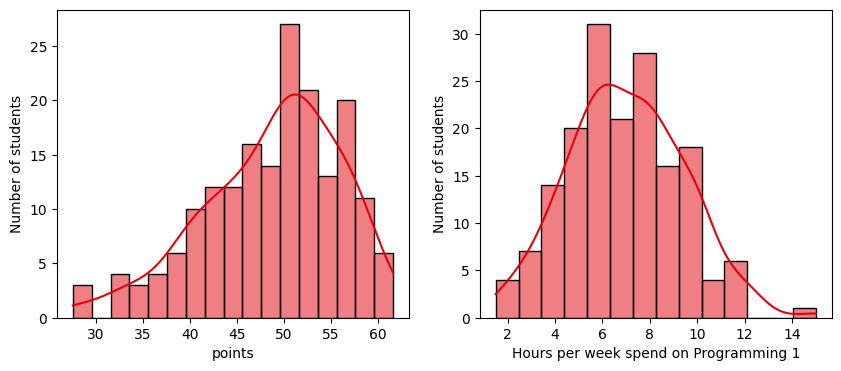

In [9]:
# Distribution points

fig,ax = plt.subplots(1,2,figsize=(10,4))
sns.histplot(data=df,x="points",binwidth=2,kde=True,ax=ax[0],color=main_color)
ax[0].set_xlabel("points")
ax[0].set_ylabel("Number of students")


# # Distribution study hours
df_hours = df[df['46']<=20] # Few outliers detected 
sns.histplot(data=df_hours,x="46",binwidth=1,kde=True,color=main_color,ax=ax[1])
# plt.title("Self-reported study hours per week")
ax[1].set_ylabel("Number of students")
ax[1].set_xlabel("Hours per week spend on Programming 1")


# Save figure to computer
fig.savefig("Figures/dist_points_hours.pdf")
plt.show()

True the kernel density estimator we can see that the AI Bachelor cohort has a normal distrubtion. The HNW bachelor cohort seems to have two two normal distributions or one with two bumps

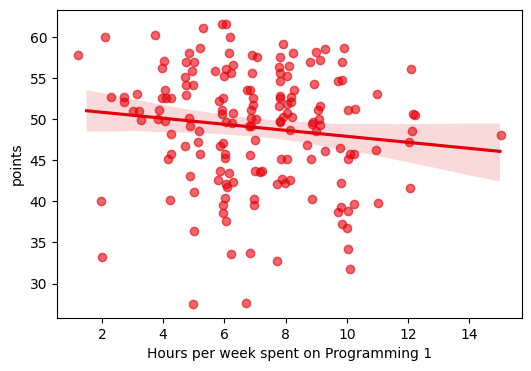

Correlation:  -0.05


In [10]:
fig,ax = plt.subplots(figsize=(6,4))
# Hours vs points
rho = df['46'].corr(df['points'])
sns.regplot(df_hours,x='46',y='points',x_jitter=0.3,scatter_kws={"alpha":0.6},color=main_color,ax=ax)
# plt.title(f"Study hours vs points (Correlation: {rho:.2f})")
ax.set_xlabel("Hours per week spent on Programming 1")
fig.savefig("Figures/hours_vs_points.pdf")
plt.show()
print("Correlation: ",f"{rho:.2f}")

In [11]:
df_strats= df["43"].dropna()

In [12]:
letter_mapping = {
    "E": "Watching the lectures (mostly in person)",
    "F": "Watching the lectures (mostly from home)",
    "A": "Revisiting the lecture slides",
    "B": "Doing extra exercises at the end of each assignment",
    "C": "Reading the recommended books",
    "D": "Doing project lovelace exercises",
    "G": "Attending the practice sessions (on Wednesdays)",
    "H": "Writing summaries of the lecture",
    "I": "Practicing together with peers",
    "J": "Using the feedback given and the self-reflection",
}

strat_df = pd.DataFrame({v:df['43'].str.contains(k,na=False)for k,v in letter_mapping.items()}) # Building Dataframe for plotting the learning strategies

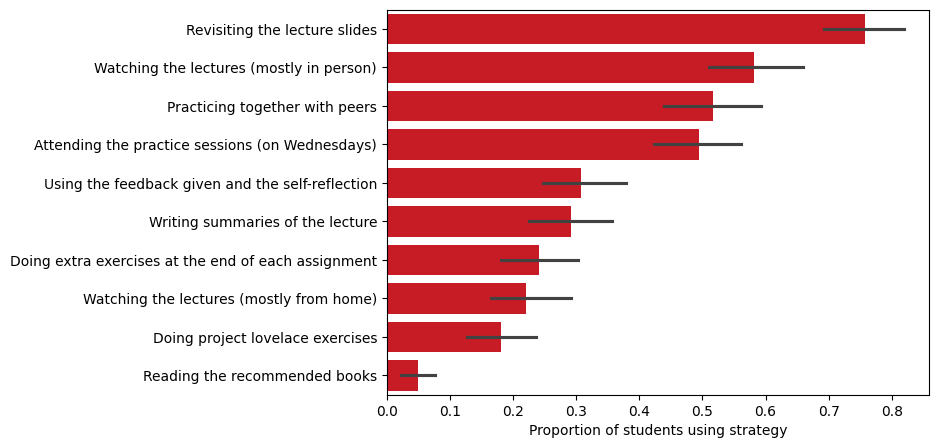

In [13]:

# Plot of learning strategies
order = strat_df.mean().sort_values(ascending=False).index # Sort proportions for better plot

fig,ax =plt.subplots(figsize=(7,5))
sns.barplot(strat_df,orient='h',order=order,color=main_color,ax=ax)
ax.set_xlabel("Proportion of students using strategy")
fig.savefig("Figures/strategies.pdf", bbox_inches='tight')
plt.show()

In [14]:
strat_df.astype(int).sum(axis=1).agg(['mean','std'])

mean    3.642857
std     1.710846
dtype: float64

In [15]:
df['46'].describe()

count    172.000000
mean       7.385465
std        4.280265
min        1.500000
25%        5.000000
50%        7.000000
75%        9.000000
max       50.000000
Name: 46, dtype: float64

In [16]:
df['points'].describe()

count    182.000000
mean      48.750755
std        7.246047
min       27.550000
25%       43.975000
50%       50.018750
75%       53.975000
max       61.600000
Name: points, dtype: float64

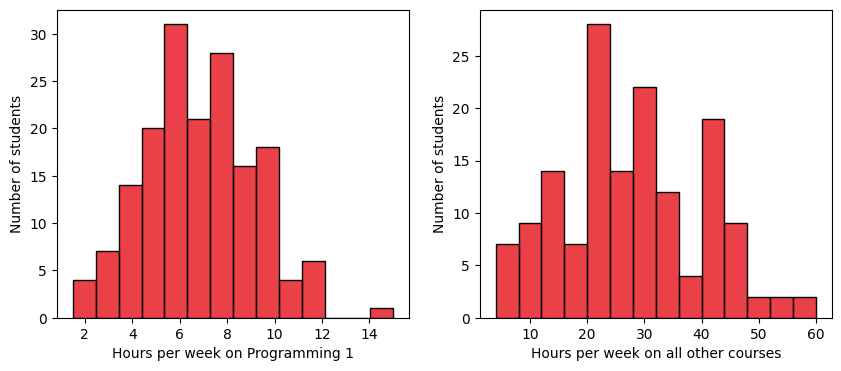

In [17]:
# Plot Histogram of hours  (46,47)\
fig,ax = plt.subplots(1,2,figsize=(10,4))

#1
sns.histplot(df_hours,x='46',binwidth=1,ax=ax[0],color=main_color)

ax[0].set_xlabel("Hours per week on Programming 1")
ax[0].set_ylabel("Number of students")

#2

sns.histplot(df_hours,x='47',binwidth=4,ax=ax[1],color=main_color)
ax[1].set_xlabel("Hours per week on all other courses")
ax[1].set_ylabel("Number of students")


plt.show()